# 📚 01 · RAG 학습 — 문서 파싱 → 청크 → BM25 · 임베딩 → FAISS
**실행 환경:** Python 3.10 · **원격 GCP g2-standard-4 (vCPU 4 · RAM 16GB) + NVIDIA L4 24GB** (로컬 RTX 5070 Ti 도 가능). 하드웨어를 감지해 배치 크기 등을 자동으로 맞춥니다.

```
ZIP ─▶ PDF      : PyPDFLoader(본문) + PyMuPDFLoader(표 Markdown · 이미지)        ← langchain_community
     ─▶ HWP/HWPX : HwpHwpxLoader(본문 · 표 Markdown · 각주 · 이미지)              ← langchain-hwp-hwpx-loader
     ─▶ 정제(머리글·쪽번호·끊긴 줄·표 중복) ─▶ 청크(700자, overlap 0.2)
     ─▶ BM25(kiwi) + HF 임베딩(KURE-v1, GPU) ─▶ FAISS   ─▶ artifacts/build_config.json 저장
```
- 이 노트북이 끝나면 **`02_generate_eval.ipynb`** 를 실행하세요. 02는 여기서 만든 인덱스를 불러와 **답변 생성과 RAGAS 평가만** 합니다. 학습·임베딩은 다시 하지 않습니다.
- ⏸ **■ (Interrupt) = 안전 중지**: 현재 문서·배치·스텝까지 저장합니다. **같은 셀을 다시 실행하면 이어서** 진행합니다. 커널이 재시작되면 `0-1 ~ 0-3`부터 다시 실행하세요.
- 질문의 규칙·사전 전처리는 하지 않습니다. 질문은 02에서 원문 그대로 사용합니다.
- **GCP 준비:** VS Code Remote-SSH(또는 JupyterHub)로 VM 에 접속 → 프로젝트 폴더와 `data/` 의 ZIP 업로드 → `.env` 에 `OPENAI_API_KEY` (HuggingFace 는 VM 터미널에서 `hf auth login` 한 번, 안 해도 공개 모델은 받아짐).
- ⚠️ **노트북은 한 번에 하나만 실행하세요** (VM RAM 16GB). 다른 노트북 커널이 남아 있으면 메모리 부족으로 커널이 강제 종료됩니다. `0-1` 셀이 다른 커널과 RAM·GPU 사용량을 보여주고, `CLOSE_OTHER_KERNELS = True` 로 정리할 수 있습니다.
- 🔎 **검색 과정 자체 평가 (2-5 ~ 2-7, $0):** 정답 문서가 정해진 질문 세트로 Dense · BM25 · 하이브리드 · 리랭커를 Hit@k · Recall@k · MRR · Precision@k · 근거 키워드로 채점하고, Dense:BM25 가중치를 스윕합니다. 결과는 `eval/results/retrieval_01.json` → `04_e2e_eval.ipynb` 가 02·03 결과와 합칩니다.
- 💵 **이 노트북은 GPT(Chat API)를 쓰지 않습니다 → API 비용 $0.** `2-4` 에서 02·03 이 쓸 리랭커 모델을 미리 받아 둡니다(내 GPU, 무료).

## 0. 환경 준비
> 👥 **담당:** PM · 통합

In [6]:
# 0-0) 패키지 설치 — 처음 한 번만. 이미 맞게 깔려 있으면 아무것도 바꾸지 않음. 새로 설치하면 여기서 멈춤 → 'Kernel → Restart'
#  ▸ Python 3.10 이상 (이 노트북의 커널 = 아래 sys.executable)
#  ▸ GCP L4(sm_89) · RTX 5070 Ti(sm_120) 모두 CUDA 12.8 빌드(cu128) PyTorch 사용 — 드라이버 525 이상(L4), 570 이상(RTX 50)
#  ▸ HWP/HWPX 로더:  python3.10 -m pip install langchain-hwp-hwpx-loader   ← 아래에서 이 커널의 python 으로 실행
import importlib.util, importlib.metadata as im, subprocess, sys

print("Python", sys.version.split()[0], "·", sys.executable)
if sys.version_info < (3, 10):
    raise RuntimeError("Python 3.10 이상 커널을 선택하세요 (langchain-hwp-hwpx-loader 요구사항)")
PIP = [sys.executable, "-m", "pip"]          # = 이 커널의 python -m pip

# ── 안전장치 ① 가상환경(.venv) 커널인지 — 시스템 파이썬(/usr/bin/python3)에 설치하면 디스크만 차고, 노트북은 .venv 패키지를 씀
import shutil
IN_VENV = sys.prefix != sys.base_prefix or "conda" in sys.prefix.lower()
if not IN_VENV:
    raise RuntimeError(f"지금 커널은 시스템 파이썬({sys.executable})입니다 → 노트북 오른쪽 위 커널 선택 ▸ Python 환경 ▸ '.venv' "
                       "(예: ~/.venv/bin/python)로 바꾼 뒤 다시 실행하세요. 시스템 파이썬에는 설치하지 않습니다.")
def disk_free_gb():
    return shutil.disk_usage(sys.prefix).free / 1024**3
def need_disk(gb, what):     # ── 안전장치 ② 디스크 여유 — 부족하면 설치 도중 'No space left on device' 로 깨진 채 남음
    if disk_free_gb() < gb:
        raise RuntimeError(f"디스크 여유 {disk_free_gb():.1f}GB < 필요 {gb}GB ({what}) → 터미널에서 '{sys.executable} -m pip cache purge', "
                           "안 쓰는 HF 모델 삭제('hf cache delete') 후 다시 실행하거나 GCP 부팅 디스크를 늘리세요. (아무것도 지우거나 설치하지 않았습니다)")
def pip(*args):              # 실패하면 원인 안내와 함께 멈춤
    r = subprocess.run(PIP + list(args))
    if r.returncode:
        raise RuntimeError(f"pip 실패(코드 {r.returncode}) — 바로 위 pip 출력의 마지막 'ERROR:' 줄이 원인입니다 "
                           f"(No space left on device = 디스크 부족 · 현재 여유 {disk_free_gb():.1f}GB)")
print(f"가상환경 ✓ {sys.prefix} · 디스크 여유 {disk_free_gb():.1f}GB")

def gpu_compute_cap():
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap,driver_version", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=20).stdout.strip().splitlines()
        name, cap, drv = [x.strip() for x in out[0].split(",")]
        return name, float(cap), drv
    except Exception:
        return None, None, None

name, cap, drv = gpu_compute_cap()
print(f"GPU: {name} · compute capability {cap} · driver {drv}")
TORCH_INDEX = "https://download.pytorch.org/whl/cu128" if cap is not None else "https://download.pytorch.org/whl/cpu"

INSTALLED = []                               # 이번 실행에서 새로 설치/교체한 것 → 있으면 커널 재시작 필요

def torch_supports_gpu():
    """지금 torch 로 이 GPU 를 실제로 쓸 수 있는지. 지원 목록에 'sm_89' 가 그대로 없어도 같은 세대(sm_8x) 커널이 있으면 동작
    (cu128·cu130 빌드 목록 = sm_75 sm_80 sm_86 sm_90 sm_100 sm_120 → L4(sm_89)는 sm_86 커널로 실행)"""
    try:
        import torch
        if cap is None:
            return True
        if not torch.cuda.is_available():      # 드라이버가 이 빌드를 못 돌림 (예: 드라이버보다 높은 CUDA 빌드)
            return False
        major = str(cap).split(".")[0]
        if not any(a.startswith(f"sm_{major}") for a in torch.cuda.get_arch_list()):
            return False
        a = torch.randn(64, 64, device="cuda", dtype=torch.float16)
        (a @ a).sum().item()                   # 실제 GPU 연산까지 확인
        return True
    except Exception:
        return False

if torch_supports_gpu() and importlib.util.find_spec("torchvision") is not None:
    import torch
    print(f"✓ PyTorch {torch.__version__} 그대로 사용 (GPU 연산 확인) — 재설치 안 함")
else:
    need_disk(8, "PyTorch CUDA 빌드 약 5GB + 작업 공간")
    print("→ PyTorch 설치/교체:", TORCH_INDEX, "— 기존 torch 를 먼저 지우지 않음 (설치가 실패하면 pip 가 기존 것을 되돌림)")
    if importlib.util.find_spec("torch") is not None:     # 잘못된 빌드(CPU용 등)만 CUDA 빌드로 교체
        pip("install", "--no-cache-dir", "--force-reinstall", "--no-deps", "torch", "torchvision", "--index-url", TORCH_INDEX)
    pip("install", "--no-cache-dir", "torch", "torchvision", "--index-url", TORCH_INDEX)   # 빠진 의존성(nvidia-*) 채우기
    INSTALLED.append("torch")

def _v(n):
    try:
        return im.version(n)
    except im.PackageNotFoundError:
        return None

# LangChain 조합: core·openai 1.x + community 0.3.31 (ragas 0.4.3 호환) — 다르면 requirements.txt 로 맞춤
def _major(n):
    return int((_v(n) or "0").split(".")[0])

stack_ok = (_major("langchain-core") >= 1 and _major("langchain-openai") >= 1
            and _v("langchain-community") == "0.3.31" and _v("ragas") == "0.4.3")
need = [m for m in ["sentence_transformers", "ragas", "faiss", "kiwipiepy", "pymupdf", "pypdf", "hwp_hwpx_parser",
                    "ipywidgets", "koreanize_matplotlib", "psutil", "huggingface_hub"] if importlib.util.find_spec(m) is None]
if need or not stack_ok:
    print("→ requirements.txt 설치 (누락:", need or "-", "· LangChain 조합 맞춤:", not stack_ok, ")")
    need_disk(3, "requirements.txt")
    pip("install", "-q", "--no-cache-dir", "-r", "requirements.txt")
    INSTALLED.append("requirements")

# ★ HWP/HWPX 로더 — python3.10 -m pip install langchain-hwp-hwpx-loader
if importlib.util.find_spec("langchain_hwp_hwpx") is None:
    print("→", " ".join(["python3.10" if sys.version_info[:2] == (3, 10) else sys.executable, "-m", "pip", "install",
                         "langchain-hwp-hwpx-loader"]))
    pip("install", "--no-cache-dir", "langchain-hwp-hwpx-loader")
    INSTALLED.append("langchain-hwp-hwpx-loader")

print({n: _v(n) for n in ("langchain-hwp-hwpx-loader", "hwp-hwpx-parser", "langchain-core", "langchain-community",
                          "langchain-openai", "ragas", "torch")})
if INSTALLED:
    # 설치한 채로 계속 실행하면 메모리에 올라간 옛 torch 와 새 파일이 섞여 커널이 불안정해짐 → 여기서 멈춤 ('모두 실행'도 중단)
    raise RuntimeError(f"설치/교체 완료({', '.join(INSTALLED)}) → 메뉴에서 Kernel ▸ Restart 후 0-1 셀부터 실행하세요 (0-0 은 다시 안 돌려도 됨)")
print("✅ 설치 확인 완료 — 바꾼 것 없음. 바로 0-1 셀로 진행하세요 (다음부터는 0-0 을 건너뛰어도 됩니다)")

Python 3.12.3 · /home/spai1322/.venv/bin/python
가상환경 ✓ /home/spai1322/.venv · 디스크 여유 20.0GB
GPU: NVIDIA L4 · compute capability 8.9 · driver 580.178.04
✓ PyTorch 2.11.0+cu128 그대로 사용 (GPU 연산 확인) — 재설치 안 함
{'langchain-hwp-hwpx-loader': '0.1.1', 'hwp-hwpx-parser': '1.0.0', 'langchain-core': '1.6.6', 'langchain-community': '0.3.31', 'langchain-openai': '1.6.7', 'ragas': '0.4.3', 'torch': '2.11.0+cu128'}
✅ 설치 확인 완료 — 바꾼 것 없음. 바로 0-1 셀로 진행하세요 (다음부터는 0-0 을 건너뛰어도 됩니다)


In [7]:
# 0-1) 경로 · 토큰(OpenAI .env / HuggingFace 로그인) · CPU/GPU 버전 확인   — 보통 10~30초
#  ▸ 원격 GCP: g2-standard-4 (vCPU 4 · RAM 16GB) + NVIDIA L4 24GB — VS Code Remote-SSH / JupyterHub 커널에서 실행
#  ▸ HuggingFace 로그인(선택, VM 터미널에서 한 번): hf auth login   ← 이후 HF_TOKEN 입력창 없음
#  ▸ ⑤ 메모리 점검: 다른 노트북 커널이 RAM·GPU 를 잡고 있으면 경고 (CLOSE_OTHER_KERNELS=True 로 종료)
import os, sys, time
from pathlib import Path

T0 = time.time()
PROJECT_DIR = Path.cwd() if (Path.cwd() / "rag").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR))
os.chdir(PROJECT_DIR)
if sys.version_info < (3, 10):
    raise RuntimeError(f"Python 3.10 이상이 필요합니다 (현재 {sys.version.split()[0]}) → 커널을 Python 3.10 으로 바꾸세요")

HF_CACHE_DIR = None        # 모델 저장 위치(기본 ~/.cache/huggingface, 약 10GB). 디스크가 부족하면 예) "/mnt/disk/hf_cache"
NEED_OPENAI  = False       # 01: 인덱스 구축에는 불필요 (입력창 안 띄움)

print("① torch 로딩…", flush=True)
from rag.hw import apply_runtime_env, detect, gpu_mem, summary, require_gpu
apply_runtime_env(cache_dir=HF_CACHE_DIR)
print(f"   완료 {time.time() - T0:.1f}s", flush=True)

print("② 토큰 — OpenAI: .env / HuggingFace: 로그인 정보(hf auth login) 사용, HF_TOKEN 입력창 없음", flush=True)
from rag.credentials import load_tokens, verify_tokens, mask
import pandas as pd
tok_status = load_tokens(PROJECT_DIR / ".env", ask=False, save_to_env=False, required=())   # 입력창을 띄우지 않음
_k = os.environ.get("OPENAI_API_KEY", "").strip()
while _k.startswith("sk-sk-"):                    # 'sk-' 가 두 번 붙은 키 바로잡기 (메모리에서만)
    _k = _k[3:]
if _k:
    os.environ["OPENAI_API_KEY"] = _k
elif NEED_OPENAI:
    import getpass
    print("🔑 OPENAI_API_KEY 가 .env 에 없습니다 → 입력창(VS Code: 창 맨 위)에 붙여넣고 Enter", flush=True)
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OPENAI_API_KEY: ").strip()
    tok_status["OPENAI_API_KEY"]["출처"] = "입력(메모리에만)"

# HuggingFace: 터미널에서 한 번 'hf auth login'(구버전: huggingface-cli login) 하면 저장된 로그인 정보를 자동 사용
from huggingface_hub import get_token
_hf = get_token() or next((p.read_text().strip() for p in [Path.home() / ".cache" / "huggingface" / "token"] if p.exists()), None)
if _hf:
    os.environ["HF_TOKEN"] = _hf
oa = os.environ.get("OPENAI_API_KEY", "")
display(pd.DataFrame({
    "OPENAI_API_KEY": {"값": mask(oa), "출처": tok_status["OPENAI_API_KEY"]["출처"] if oa else "-",
                       "용도": "gpt-5-mini 생성·RAGAS 심판" + ("" if NEED_OPENAI else " (01 에서는 파인튜닝 QA 생성 때만)")},
    "HuggingFace": {"값": "로그인됨" if _hf else "로그인 안 됨", "출처": "hf auth login" if _hf else "-",
                    "용도": "모델 다운로드 (KURE-v1·Qwen2.5-VL 은 공개 모델이라 로그인 없이도 받아짐)"},
}).T)
print("③ 토큰 검증 (각 최대 15초)", flush=True)
tok_check = verify_tokens("gpt-5-mini")
print("검증:", tok_check)
if NEED_OPENAI and any(e in tok_check.get("OPENAI_API_KEY", "") for e in ("AuthenticationError", "PermissionDeniedError", "NotFoundError")):
    raise RuntimeError(f"OpenAI 키를 쓸 수 없습니다: {tok_check['OPENAI_API_KEY']} · 현재 키 {mask(os.environ.get('OPENAI_API_KEY'))}"
                       " → .env 의 OPENAI_API_KEY 확인 후 이 셀을 다시 실행하세요")

print("④ GPU 점검", flush=True)
REQUIRE_GPU = True          # True: GPU(GCP L4 / 로컬 5070 Ti)를 못 쓰면 CPU 로 넘어가지 않고 원인을 알려주며 중단
HW = detect()
from rag.hw import hw_table
display(hw_table(HW).rename(columns={"값": "지금 사용 중인 CPU · GPU · 버전"}))
if HW.get("gpu"):
    print(("✅ " if HW.get("kernel_ok") else "❌ ") + str(HW.get("kernel_msg")))
print(gpu_mem())
if REQUIRE_GPU:
    require_gpu(HW)
print("⑤ 메모리 점검", flush=True)
# ⑤ 메모리 점검 — VM RAM 16GB: 다른 노트북 커널이 남아 있으면 메모리가 모자라 리눅스가 커널을 강제 종료(OOM)합니다
CLOSE_OTHER_KERNELS = False   # True: 이 노트북 말고 떠 있는 다른 Jupyter 커널을 종료해 RAM·GPU 확보 (그 노트북들의 변수는 사라짐)
import psutil, subprocess
def _gb(b): return round(b / 1024**3, 1)
_me = psutil.Process()
_gpu = {}
try:
    _o = subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv,noheader,nounits"],
                        capture_output=True, text=True, timeout=10).stdout
    for _ln in _o.strip().splitlines():
        _p, _m = [x.strip() for x in _ln.split(",")]
        _gpu[int(_p)] = round(int(_m) / 1024, 1)
except Exception:
    pass
_others = []
for _p in psutil.process_iter(["pid", "cmdline", "memory_info", "create_time"]):
    try:
        _cl = _p.info["cmdline"] or []
        if (_p.info["pid"] != _me.pid and _cl and "python" in os.path.basename(_cl[0]).lower()
                and any("ipykernel" in a for a in _cl[1:])):          # 다른 노트북 커널 (python -m ipykernel_launcher …)
            _others.append(_p)
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass
if _others:
    display(pd.DataFrame([{"PID": p.pid, "RAM(GB)": _gb(p.info["memory_info"].rss), "GPU(GB)": _gpu.get(p.pid, 0.0),
                           "켜진 지(분)": int((time.time() - p.info["create_time"]) / 60)} for p in _others])
            .set_index("PID").rename_axis("다른 Jupyter 커널"))
    if CLOSE_OTHER_KERNELS:
        for p in _others:
            p.terminate()
        _gone, _alive = psutil.wait_procs(_others, timeout=8)
        for p in _alive:
            p.kill()
        print(f"🧹 다른 커널 {len(_others)}개 종료 → RAM·GPU 반환", flush=True)
        time.sleep(2)
    else:
        print(f"⚠️ 다른 Jupyter 커널 {len(_others)}개가 RAM {sum(_gb(p.info['memory_info'].rss) for p in _others):.1f}GB · "
              f"GPU {sum(_gpu.get(p.pid, 0) for p in _others):.1f}GB 를 쓰고 있습니다 → 메모리 부족으로 커널이 강제 종료될 수 있음\n"
              f"   끄는 법: 해당 노트북에서 커널 종료(Shut Down) · 터미널 'kill {' '.join(str(p.pid) for p in _others)}' · "
              "또는 위 CLOSE_OTHER_KERNELS = True 후 이 셀 재실행", flush=True)
_vm, _sw = psutil.virtual_memory(), psutil.swap_memory()
print(f"RAM 사용 가능 {_gb(_vm.available)} / {_gb(_vm.total)}GB · 이 커널 {_gb(_me.memory_info().rss)}GB · "
      f"스왑 {_gb(_sw.total)}GB · {gpu_mem()}", flush=True)
if _vm.available < 4 * 1024**3:
    print("⚠️ 사용 가능한 RAM 이 4GB 미만입니다 → 다른 커널을 끄거나, 노트북은 한 번에 하나만 실행하세요", flush=True)
if _sw.total == 0:
    print("ℹ️ 스왑이 없습니다. 메모리가 잠깐 모자랄 때 커널이 바로 죽지 않게 하려면 VM 터미널에서 한 번:\n"
          "   sudo fallocate -l 8G /swapfile && sudo chmod 600 /swapfile && sudo mkswap /swapfile && sudo swapon /swapfile", flush=True)
print(f"⏱ 총 {time.time() - T0:.1f}s")

① torch 로딩…
   완료 0.0s
② 토큰 — OpenAI: .env / HuggingFace: 로그인 정보(hf auth login) 사용, HF_TOKEN 입력창 없음
✔ .env 읽음: /home/spai1322/rfg_rag/.env  (키: OPENAI_API_KEY)


,값,출처,용도
OPENAI_API_KEY,sk-pr…6mQA,.env,gpt-5-mini 생성·RAGAS 심판 (01 에서는 파인튜닝 QA 생성 때만)
HuggingFace,로그인 안 됨,-,모델 다운로드 (KURE-v1·Qwen2.5-VL 은 공개 모델이라 로그인 없이도 받아짐)


③ 토큰 검증 (각 최대 15초)
… OpenAI 키 확인 중


  (0.6s)
검증: {'OPENAI_API_KEY': '✅ 유효 · gpt-5-mini 접근 가능', 'HF_TOKEN': '— 미설정 (공개 모델은 토큰 없이도 받을 수 있음)'}
④ GPU 점검
… GPU 커널 점검 중 (첫 실행은 CUDA 초기화로 수 초~수십 초)


,지금 사용 중인 CPU · GPU · 버전
CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
CPU 코어·스레드,물리 2코어 / 논리 4스레드
RAM,15.6 GB
GPU,NVIDIA L4
GPU 메모리,22.0 GB
GPU 아키텍처,sm_89 · bf16 지원
NVIDIA 드라이버,580.178.04
PyTorch,2.11.0+cu128
CUDA (torch 빌드),12.8
cuDNN,9.19.0


✅ CUDA 커널 실행 OK (fp16/bf16 matmul, softmax) (0.0s)
GPU 메모리: 이 프로세스 0.01GB(예약 0.02GB) · 장치 여유 21.8 / 22.0GB
⑤ 메모리 점검
RAM 사용 가능 6.6 / 15.6GB · 이 커널 1.5GB · 스왑 0.0GB · GPU 메모리: 이 프로세스 0.01GB(예약 0.02GB) · 장치 여유 21.8 / 22.0GB
ℹ️ 스왑이 없습니다. 메모리가 잠깐 모자랄 때 커널이 바로 죽지 않게 하려면 VM 터미널에서 한 번:
   sudo fallocate -l 8G /swapfile && sudo chmod 600 /swapfile && sudo mkswap /swapfile && sudo swapon /swapfile
⏱ 총 0.7s


In [8]:
# 0-2) ★★ 학습(인덱스 구축) 하이퍼파라미터 — 이 셀만 고치면 이후 모든 단계에 반영 ★★
# ─────────────────────────────────────────── 경로
ZIP_PATH, WORK_DIR = "/home/spai1322/RAG_pr_Rep.zip", "artifacts"  # GCP: 프로젝트 폴더의 data/ 에 ZIP 업로드 (리눅스 경로, D:/ 같은 윈도우 경로 X)

# ─────────────────────────────────────────── 📄 로더 (모두 라이브러리)
PDF_TEXT_LOADER  = "PyPDFLoader"     # PDF 본문: "PyPDFLoader" | "PyMuPDFLoader"
PDF_TABLE_LOADER = "PyMuPDFLoader"   # PDF 표 : "PyMuPDFLoader"(extract_tables="markdown") | None
PYPDF = dict(mode="page", extraction_mode="plain", extraction_kwargs={})   # PyPDFLoader 옵션 (plain | layout)
TABLE_SETTINGS = {}                  # PyMuPDFLoader extract_tables_settings (예: {"strategy": "lines_strict"})
HWP = dict(                          # HwpHwpxLoader (langchain-hwp-hwpx-loader) 옵션
    table_style="MARKDOWN",          # MARKDOWN | CSV | INLINE   (표는 본문 제자리에 들어옴)
    include_notes=True,              # 각주·미주
    include_memos=False,
    include_hyperlinks=False,
)
HWP_FRONT_MATTER = "auto"            # HWP 는 쪽 정보가 없음 → 표지·목차를 자동 감지해 제외 | "none"
IMAGE_PARSER = "auto"                # "auto"(GPU면 hf-vlm) | "hf-vlm" | "rapidocr" | "tesseract" | "llm" | None
VLM_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"
VLM_MAX_PIXELS = None               # None = GPU 프로필(L4: 1024·28·28). 로컬 5070 Ti 에서 파싱한 캐시를 그대로 쓰려면 768*28*28

# ─────────────────────────────────────────── 🔍 파싱 정확도
PARSING = dict(
    skip_first_pages=2,              # PDF: 앞 N쪽(표지·목차) 제외
    hanja_mode="append",             # none | append(必(필)) | replace(필)
    extract_tables=True,
    remove_page_numbers=True,        # '- 3 -', '3/19' 줄 제거
    repeated_line_ratio=0.5,         # 이 비율 이상 쪽에 반복되는 줄 = 머리글/바닥글 → 제거
    drop_table_text_from_body=True,  # PyPDFLoader 본문에 평문으로 섞인 표 내용 제거 (표는 Markdown 청크로)
    table_dedupe_threshold=0.85,
    join_broken_lines=True,          # PDF 줄바꿈으로 끊긴 문장 잇기
    join_min_line_len=20,
    fix_bullet_glyphs=True,          # 깨진 글머리(Ÿ) → •
)

# ─────────────────────────────────────────── ✂️ 청크
CHUNK_SIZE            = 700                  # 글자 단위
CHUNK_SIZE_CANDIDATES = [400, 700, 1000]     # 1-3 셀에서 비교
OVERLAP_RATIO         = 0.2                  # overlap = 700 × 0.2 = 140자
SEPARATORS = ["문단", "Ⅰ.", "1.", "가.", "1)", "○", "□", "-", "※", "줄바꿈", "문장", "공백"]  # 앞일수록 우선
SECTION_HEADERS = True

# ─────────────────────────────────────────── 🧠 임베딩 · 🗂 FAISS · 🔤 BM25
EMBED_MODEL = "nlpai-lab/KURE-v1"            # 대안: "BAAI/bge-m3", "dragonkue/BGE-m3-ko"
EMBED_BATCH = None                           # None = GPU 프로필 (GCP L4: 64 · 5070 Ti: 32)
SHARD_EVERY = 10                             # N배치마다 임베딩 샤드 저장(=체크포인트)
FAISS_CFG = dict(index_type="flat", metric="ip", hnsw_m=32, hnsw_ef_construction=200, hnsw_ef_search=128)
BM25_CFG  = dict(tokenizer="kiwi", k1=1.5, b=0.75)

# ============ 적용 (하드웨어 프로필 → 위 값 순서로 덮어씀) ============
from rag.config import load_config, set_by_path
from rag.hw import profile_overrides, profile_name
CFG = load_config()
for k, v in profile_overrides(HW).items():
    set_by_path(CFG, k, v)
CFG["paths"].update(input=ZIP_PATH, work_dir=WORK_DIR)
CFG["parsing"].update(PARSING, pdf_text_loader=PDF_TEXT_LOADER, pdf_table_loader=PDF_TABLE_LOADER, pypdf=PYPDF,
                      table_settings=TABLE_SETTINGS, hwp_loader="HwpHwpxLoader", hwp=HWP,
                      vlm_model=VLM_MODEL, hwp_front_matter=HWP_FRONT_MATTER)
if IMAGE_PARSER != "auto":
    CFG["parsing"]["image_parser"] = IMAGE_PARSER
if VLM_MAX_PIXELS:
    CFG["parsing"]["vlm_max_pixels"] = int(VLM_MAX_PIXELS)
CFG["chunking"].update(chunk_size=CHUNK_SIZE, overlap_ratio=OVERLAP_RATIO, chunk_overlap=None,
                       separators=SEPARATORS, section_headers=SECTION_HEADERS)
CFG["embedding"].update(model=EMBED_MODEL, shard_every_batches=SHARD_EVERY)
if EMBED_BATCH: CFG["embedding"]["batch_size"] = EMBED_BATCH
CFG["faiss"].update(FAISS_CFG); CFG["bm25"].update(BM25_CFG)
print("프로필:", profile_name(HW), "| PDF:", PDF_TEXT_LOADER, "+", PDF_TABLE_LOADER, "| HWP: HwpHwpxLoader",
      "| 이미지:", CFG["parsing"].get("image_parser"), f"| chunk {CHUNK_SIZE} · overlap {int(CHUNK_SIZE * OVERLAP_RATIO)}자",
      "| 임베딩 batch", CFG["embedding"]["batch_size"], CFG["embedding"]["device"])
if not Path(ZIP_PATH).exists():
    print(f"⚠️ {ZIP_PATH} 가 없습니다 → VM 의 {PROJECT_DIR / ZIP_PATH} 위치에 ZIP 을 올리거나 ZIP_PATH 를 고치세요")
print(f"RAM {HW['ram_gb']}GB · vCPU {HW['cpus']} · DataLoader worker {CFG['finetune']['dataloader_num_workers']} · VLM 해상도 상한 {CFG['parsing'].get('vlm_max_pixels')}")

프로필: gpu-24gb (L4/A10/4090) | PDF: PyPDFLoader + PyMuPDFLoader | HWP: HwpHwpxLoader | 이미지: hf-vlm | chunk 700 · overlap 140자 | 임베딩 batch 64 cuda
RAM 15.6GB · vCPU 4 · DataLoader worker 2 · VLM 해상도 상한 802816


In [9]:
# 0-3) 파이프라인 · 헬퍼 · 사용 라이브러리 버전
from rag.pipeline import Pipeline
from rag import notebook_checkpoint as nb
pd.set_option("display.max_colwidth", 120)
# Windows(로컬)에서 만든 artifacts 를 GCP(리눅스)로 옮겨 온 경우: 저장된 경로의 '\' → '/' 로 바꿔야 파일을 찾음
def fix_windows_paths(work_dir):
    import json as _json
    if os.sep == "\\" or not Path(work_dir).exists():
        return 0
    n = 0
    def conv(x):
        nonlocal n
        if isinstance(x, str) and "\\" in x and ("artifacts" in x or x.startswith(str(work_dir))):
            n += 1
            return x.replace("\\", "/")
        if isinstance(x, dict):
            return {k: conv(v) for k, v in x.items()}
        if isinstance(x, list):
            return [conv(v) for v in x]
        return x
    for name in ("active.json", "build_config.json", "manifest.json"):
        p = Path(work_dir) / name
        if p.exists():
            d = _json.loads(p.read_text(encoding="utf-8"))
            d2 = conv(d)
            if d2 != d:
                p.write_text(_json.dumps(d2, ensure_ascii=False, indent=2), encoding="utf-8")
    return n
_n = fix_windows_paths(WORK_DIR)
if _n:
    print(f"ℹ️ Windows 에서 만든 artifacts 감지 → 경로 {_n}개를 리눅스 형식으로 변환했습니다")
pipe = Pipeline(CFG)

import importlib.metadata as im
def _ver(*names):
    for n in names:
        try:
            return im.version(n)
        except im.PackageNotFoundError:
            continue
    return "-"
display(pd.DataFrame({n: _ver(*n.split("|")) for n in ["langchain-hwp-hwpx-loader", "hwp-hwpx-parser", "langchain-community", "langchain-core", "pypdf", "pymupdf", "faiss-cpu|faiss-gpu|faiss-gpu-cu12", "sentence-transformers", "torch", "kiwipiepy"]}, index=["버전"]))

,langchain-hwp-hwpx-loader,hwp-hwpx-parser,langchain-community,langchain-core,pypdf,pymupdf,faiss-cpu|faiss-gpu|faiss-gpu-cu12,sentence-transformers,torch,kiwipiepy
버전,0.1.1,1.0.0,0.3.31,1.6.6,6.19.0,1.28.2,1.15.1,6.1.0,2.11.0+cu128,0.24.0


## 1. 문서 → 텍스트 (라이브러리 로더)
> 👥 **담당:** 문서 파싱 (1-1 · 1-2 · 1-4) · 청크 · 색인 (1-3) — `rag/parsing.py` `text_utils.py` `vision.py` `chunk_split.py`

In [10]:
# 1-1) 라이브러리를 직접 호출해서 무엇이 나오는지 확인
from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader
from langchain_hwp_hwpx import HwpHwpxLoader                       # pip install langchain-hwp-hwpx-loader
from hwp_hwpx_parser import ExtractOptions, TableStyle, ImageMarkerStyle
from rag.pipeline import collect_inputs
from rag.text_utils import clean_tab_garbage, repair_md_tables, split_front_matter

files = collect_inputs(CFG["paths"]["input"], str(Path(WORK_DIR) / "raw"))
pdfs = [f for f in files if f.lower().endswith(".pdf")]
hwps = [f for f in files if f.lower().endswith((".hwp", ".hwpx"))]
print(f"문서 {len(files)}개 (PDF {len(pdfs)} / HWP·HWPX {len(hwps)})\n")
if pdfs:
    pages = PyPDFLoader(pdfs[0], mode=PYPDF["mode"], extraction_mode=PYPDF["extraction_mode"]).load()
    p = min(PARSING["skip_first_pages"], len(pages) - 1)
    print(f"📄 PyPDFLoader — {Path(pdfs[0]).name} p.{p + 1} (본문)\n", pages[p].page_content[:500], "\n")
    mu = PyMuPDFLoader(pdfs[0], mode="page", extract_tables="markdown").load()
    tbl = next((d.page_content[d.page_content.find("|"):][:500] for d in mu[p:] if "|---" in d.page_content), "(표 없음)")
    print("📊 PyMuPDFLoader(extract_tables='markdown') — 첫 표\n", tbl, "\n")
if hwps:
    hdocs = HwpHwpxLoader(hwps[0], mode="single",
                          extract_options=ExtractOptions(table_style=getattr(TableStyle, HWP["table_style"]),
                                                         image_marker=ImageMarkerStyle.WITH_NAME),
                          include_tables=False,            # 표는 본문 제자리에 Markdown 으로 이미 들어옴
                          include_notes=HWP["include_notes"], include_memos=HWP["include_memos"],
                          include_hyperlinks=HWP["include_hyperlinks"]).load()
    raw = hdocs[0].page_content
    meta = {k: hdocs[0].metadata.get(k) for k in ("file_type", "loader", "parser", "element_type")}
    print(f"📝 HwpHwpxLoader — {Path(hwps[0]).name}: Document {len(hdocs)}개 · {len(raw):,}자 · 표 줄 {raw.count(chr(10) + '|')}개\n   {meta}")
    txt, fixed = repair_md_tables(clean_tab_garbage(raw))
    front, body, how = split_front_matter(txt)
    print(f"   표지·목차 감지: {how} (제외 {len(front)}자) · 병합셀 보정 {fixed}행\n   본문 시작 ▶", body.lstrip()[:300])

문서 98개 (PDF 4 / HWP·HWPX 94)

📄 PyPDFLoader — 고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf p.3 (본문)
 -3- 
 
 
 
 
 
2. 제안서 작성 유의사항 ························································································  242 
3. 제안서 목차 및 작성방법 ···················································································  244 
 
[별첨] ················································································································  248~297 

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
📊 PyMuPDFLoader(extract_tables='markdown') — 첫 표
 |Col1|고려대학교 차세대 포털·학사 정보시스템 구축 사업|Col3|
|---|---|---|


|정보시스템|주요내용|비고|
|---|---|---|
|포털시스템|­ 통합로그인, 통합/지능형 검색, 마이페이지, 공지/알림, 일정관리,<br>커뮤니티, 게시판, 사용자별 정보서비스, 위젯, 연계서비스(웹메일,<br>챗봇, 전자결재, 학사/행정 서비스) 등<br>­ 학생(졸업생포함), 교직원, 연구원 등 내부 구성원 대상 포털<br>­ 학생/교수 등 신분별개인별 주요 정보 제공<br>­ 학사/행정/연구 시스템의 주요 기능 직접 접근<br>­ 위젯 등 개인화-SSO(기존 보유, 활용), 간편인증, 2차인증적용<br>­ 사용자 통합관리-포털, 홈페이지, 교내 정보시스템의 웹 페이지<br>및 메뉴, 첨부 문서 검색<br>­ 검색자의 신분

In [11]:
# 1-2) 전체 파싱 + 청크 (문서 1개마다 저장 → 중단 후 재개) + 파싱 품질 표
docs, chunks = nb.run(pipe, pipe.prepare_chunks) or (None, None)
if docs:
    quality = nb.show_parse_quality(docs)

[extract] 문서 98개 (PDF 4 / HWP 94)
[vlm] loading Qwen/Qwen2.5-VL-3B-Instruct ... (최초 1회 다운로드)


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[parse] (1/98) (사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp: 표지·목차: 목차 표시만 감지 줄 8 → 287블록 (109.5s)
[parse] (2/98) (사)부산국제영화제_2024년 BIFF & ACFM 온라인서비스 재개발 및 행사지원시.hwp: 표지·목차: 목차 첫 항목 재등장 줄 63 → 141블록 (26.5s)
[parse] (3/98) (사）한국대학스포츠협의회_KUSF 체육특기자 경기기록 관리시스템 개발.hwp: 표지·목차: 목차(쪽번호) 감지 줄 8~11 → 198블록 (3.1s)
[parse] (4/98) (재)예술경영지원센터_통합 정보시스템 구축 사전 컨설팅.hwp: 표지·목차: 첫 제목 감지 줄 21 → 142블록 (35.9s)
[parse] (5/98) 2025 구미 아시아육상경기선수권대회 조직위원회_2025 구미아시아육상경.hwp: 표지·목차: 첫 제목 감지 줄 30 → 133블록 (17.2s)
[parse] (6/98) BioIN_의료기기산업 종합정보시스템(정보관리기관) 기능개선 사업(2차).hwp: 표지·목차: 목차 표시만 감지 줄 13 → 200블록 (4.2s)
[parse] (7/98) KOICA 전자조달_[긴급] [지문] [국제] 우즈베키스탄 열린 의정활동 상하원 .hwp: 표지·목차: 목차(쪽번호) 감지 줄 10~12 → 277블록 (73.6s)
[parse] (8/98) 경기도 안양시_호계체육관 배드민턴장 및 탁구장 예약시스템 구축 용역.hwp: 표지·목차: 첫 제목 감지 줄 11 → 175블록 (11.1s)
[parse] (9/98) 경기도 평택시_2024년도 평택시 버스정보시스템(BIS) 구축사업.hwp: 표지·목차: 첫 제목 감지 줄 5 → 187블록 (20.8s)
[parse] (10/98) 경기도사회서비스원_2024년 통합사회정보시스템 운영지원.hwp: 표지·목차: 목차(쪽번호) 감지 줄 18~21 → 162블록 (1.0s)
[parse] (11/98) 경상북도 봉화군_

,문서,형식,쪽(유지),서두 제외,본문자,표,표문자,이음줄,표중복제거,머리글제거,쪽번호제거,빈쪽,깨진문자,병합셀 보정,그림,쪽당 글자,표지(라우팅용)
0,(사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화,hwp,NaN,목차 표시만 감지 줄 8,24219,214,94909,0,0,0,0,0,0,107,0,NaN,150
1,(사)부산국제영화제_2024년 BIFF & ACFM 온라인서비,hwp,NaN,목차 첫 항목 재등장 줄 63,14629,101,45763,0,0,0,0,0,0,174,1,NaN,690
2,(사）한국대학스포츠협의회_KUSF 체육특기자 경기기록 관리시스,hwp,NaN,목차(쪽번호) 감지 줄 8~11,13030,143,70343,0,0,0,0,0,0,58,0,NaN,475
3,(재)예술경영지원센터_통합 정보시스템 구축 사전 컨설팅.hwp,hwp,NaN,첫 제목 감지 줄 21,17584,83,32194,0,0,0,0,0,0,78,3,NaN,322
4,2025 구미 아시아육상경기선수권대회 조직위원회_2025 구미,hwp,NaN,첫 제목 감지 줄 30,13348,83,41069,0,0,0,0,0,0,172,0,NaN,796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,한국철도공사 (용역)_[재공고][긴급][협상형]운행정보기록 자,hwp,NaN,첫 제목 감지 줄 19,40055,153,82814,0,0,0,0,0,0,146,0,NaN,314
94,한국철도공사 (용역)_모바일오피스 시스템 고도화 용역(총체 및,hwp,NaN,첫 제목 감지 줄 19,40735,224,112233,0,0,0,0,0,0,253,1,NaN,350
95,한국철도공사 (용역)_예약발매시스템 개량 ISMP 용역.hwp,hwp,NaN,첫 제목 감지 줄 19,30713,107,52008,0,0,0,0,0,0,107,2,NaN,324
96,한국해양조사협회_2024년 항해용 간행물 품질관리 업무보조 시,hwp,NaN,목차(쪽번호) 감지 줄 13~72,32242,75,32105,0,0,0,0,0,0,94,0,NaN,1507


In [12]:
# 1-3) 청크 크기 후보 비교 (400 / 700 / 1000) — GPU·API 없이
#   CHUNK_CMP_BM25 = False : 청크 수·길이·문장 중간 절단 통계만 (수 초)
#   CHUNK_CMP_BM25 = True  : + BM25 근거 적중률. 후보 크기마다 전체 청크를 형태소 분석(Kiwi)하므로 문서 100개 기준 수 분.
#                            eval/eval_questions.yaml 의 질문·핵심사실(must_include)이 'RFP 문서 내용'일 때만 의미 있음
#                            (지금 들어 있는 연말정산 질문은 RFP 문서에 답이 없어 적중률이 모두 0 에 가깝게 나옵니다)
CHUNK_CMP_BM25 = False
from rag.evaluate import load_eval_set
EVAL_ITEMS = load_eval_set(CFG["evaluation"]["eval_set"]) if CHUNK_CMP_BM25 and Path(CFG["evaluation"]["eval_set"]).exists() else []
size_cmp = nb.compare_chunk_sizes(docs, CFG["chunking"], CHUNK_SIZE_CANDIDATES, EVAL_ITEMS, None, top_k=5,
                                  bm25_cfg=BM25_CFG, bm25_hit=CHUNK_CMP_BM25)
print("→ 적중률이 같다면 청크 수가 적고 '문장 중간 절단'이 낮은 크기를 고르세요. 바꾸려면 0-2 의 CHUNK_SIZE 수정 후 1-2부터 재실행")

⏳ 청크 크기 비교 준비…

,chunk_size,overlap,청크 수,본문,표,평균 길이,중앙값,문장 중간 절단(%),섹션 부착(%)
0,400,80,25091,8560,16401,334.3,332,42.6,94.0
1,700,140,17695,4986,12629,473.9,445,45.0,93.8
2,1000,200,15203,3476,11656,548.3,455,48.5,93.9


→ 적중률이 같다면 청크 수가 적고 '문장 중간 절단'이 낮은 크기를 고르세요. 바꾸려면 0-2 의 CHUNK_SIZE 수정 후 1-2부터 재실행


In [13]:
# 1-4) 청크 미리보기: 섹션 경로가 붙은 본문 / 표 / 그림 설명 / 한자 병기
nb.show_chunks(chunks, kind="text", n=1)
nb.show_chunks(chunks, kind="table", n=1)
nb.show_chunks(chunks, kind="image_caption", n=1)
import re
hanja = [c for c in chunks if re.search(r"[一-鿿]\([가-힣]+\)", c["text"])]
print("한자 병기 청크:", len(hanja), [re.findall(r"[一-鿿]+\([가-힣]+\)", c["text"])[:3] for c in hanja[:3]])

**사_벤처기업협회_2024년_벤처확인종합관리시스템_기능_고도화_용역사업_cf048e::c00000** · `text` · 133자

```
문서: (사)벤처기업협회 2024년 벤처확인종합관리시스템 기능 고도화 용역사업
목 차
1. 추진개요 3
2. 추진방안 5
3. 추진내용 9
4. 제안요청내용 24
5. 입찰관련사항 78
6. 제안서작성요령 82
7. 별지서식 및 붙임 94
```

(조건에 맞는 청크 4986개 중 1개 표시)


**사_벤처기업협회_2024년_벤처확인종합관리시스템_기능_고도화_용역사업_cf048e::c00056** · `table` · 105자

```
문서: (사)벤처기업협회 2024년 벤처확인종합관리시스템 기능 고도화 용역사업 | 섹션: 7. 별지서식 및 붙임 94
| 1 | | 추진배경 및 방향 |
| --- | --- | --- |
```

(조건에 맞는 청크 12629개 중 1개 표시)


**사_부산국제영화제_2024년_BIFF_ACFM_온라인서비스_재개발_및_행_59211e::c00066** · `image_caption` · 422자

```
문서: (사)부산국제영화제 2024년 BIFF & ACFM 온라인서비스 재개발 및 행사지원시 | 섹션: 2. 과업의 내용 > 나. 사이트 운영 현황
[그림/도표 설명] 이미지 내용을 정리해 드리겠습니다.

1. 그래프/차트이면:
- 제목: [제목]
- 축: [축1], [축2]
- 범례: [범례]
- 핵심 수치와 추세: [수치1] (추세), [수치2] (추세)

2. 표이면:
| 열1 | 열2 | 열3 |
|-----|-----|-----|
| [값1] | [값2] | [값3] |

3. 조직도/개념도/흐름도이면:
- 구성요소 1: [요소1]
- 구성요소 2: [요소2]
- 구성요소 3: [요소3]
- [요소1]과 [요소2] 사이의 관계: [관계1]
- [요소2]와 [요소3] 사이의 관계: [관계2]

4. 로고, 사진, 장식 이미지이면:
SKIP
```

(조건에 맞는 청크 80개 중 1개 표시)
한자 병기 청크: 236 [['本(본)', '內(내)'], ['中(중)'], ['中(중)', '中(중)']]


## 2. 인덱스 학습 — BM25(CPU) → 임베딩(GPU, 체크포인트) → FAISS
> 👥 **담당:** 청크 · 색인 — `rag/indexing.py` `pipeline.py` `notebook_checkpoint.py`

In [14]:
# 2-1a) BM25 색인 (CPU, kiwi 형태소)
nb.run(pipe, pipe.stage_bm25, chunks)

[bm25] tokenized 2000/17695
[bm25] tokenized 4000/17695
[bm25] tokenized 6000/17695
[bm25] tokenized 8000/17695
[bm25] tokenized 10000/17695
[bm25] tokenized 12000/17695
[bm25] tokenized 14000/17695
[bm25] tokenized 16000/17695
[bm25] tokenized 17695/17695
[bm25] 토큰 2,466,434 / 어휘 17,552
⏱ 90.3s · GPU 메모리: 이 프로세스 0.01GB(예약 0.02GB) · 장치 여유 21.8 / 22.0GB


In [15]:
# 2-1b) HF 임베딩(GPU, N배치마다 샤드 저장) → FAISS.   ■ 후 재실행 → 저장된 샤드 다음부터
nb.run(pipe, pipe.stage_embed_index, chunks)

[embed] nlpai-lab/KURE-v1 on cuda — 17695 chunks


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.3k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

[embed] 640/17695 (16.4 chunks/s) — 샤드 저장
[embed] 1280/17695 (27.9 chunks/s) — 샤드 저장
[embed] 1920/17695 (36.3 chunks/s) — 샤드 저장
[embed] 2560/17695 (42.8 chunks/s) — 샤드 저장
[embed] 3200/17695 (48.0 chunks/s) — 샤드 저장
[embed] 3840/17695 (52.2 chunks/s) — 샤드 저장
[embed] 4480/17695 (55.7 chunks/s) — 샤드 저장
[embed] 5120/17695 (58.6 chunks/s) — 샤드 저장
[embed] 5760/17695 (61.2 chunks/s) — 샤드 저장
[embed] 6400/17695 (63.5 chunks/s) — 샤드 저장
[embed] 7040/17695 (65.5 chunks/s) — 샤드 저장
[embed] 7680/17695 (67.2 chunks/s) — 샤드 저장
[embed] 8320/17695 (68.7 chunks/s) — 샤드 저장
[embed] 8960/17695 (70.0 chunks/s) — 샤드 저장
[embed] 9600/17695 (71.2 chunks/s) — 샤드 저장
[embed] 10240/17695 (72.3 chunks/s) — 샤드 저장
[embed] 10880/17695 (73.2 chunks/s) — 샤드 저장
[embed] 11520/17695 (74.2 chunks/s) — 샤드 저장
[embed] 12160/17695 (75.0 chunks/s) — 샤드 저장
[embed] 12800/17695 (75.7 chunks/s) — 샤드 저장
[embed] 13440/17695 (76.5 chunks/s) — 샤드 저장
[embed] 14080/17695 (77.1 chunks/s) — 샤드 저장
[embed] 14720/17695 (77.6 chunks/s) — 샤드 저장
[emb

In [16]:
# 2-2) 🗂 FAISS 직접 확인 (LLM 호출 없음)
retriever = pipe.load_retriever()
store = retriever.store                               # langchain_community.vectorstores.FAISS
print(type(store).__name__, "| faiss index:", type(store.index).__name__, "| 벡터", store.index.ntotal, "| 거리:", store.distance_strategy)
for doc, score in store.similarity_search_with_score("사업 예산과 사업 기간", k=3):
    print(f"  {score:.3f}  {doc.metadata['source'][:30]} {doc.metadata.get('section', '')[:40]}")
print("라우터 기관→문서(파일명·표지 자동 추출):", {o: len(d) for o, d in retriever.router.org_docs.items()} if retriever.router else "비활성")

FAISS | faiss index: IndexFlatIP | 벡터 17695 | 거리: DistanceStrategy.MAX_INNER_PRODUCT
  0.634  서민금융진흥원_서민금융진흥원 서민금융 채팅 상담시스템  Ⅳ. 기타 > 3. 사업 종료시 지출금액 조정을 통해 위약금 정산
  0.631  울산광역시_2024년 버스정보시스템 확대 구축 및 기능 1. 사업일반
  0.629  광주과학기술원_학사시스템 기능개선 사업.hwp 3. 사업 종료시 지출금액 조정을 통해 위약금 정산
라우터 기관→문서(파일명·표지 자동 추출): {'벤처기업협회': 1, '한국대학': 1, '예술경영지원센터': 1, '한국보건산업진흥원': 1, '한국국제협력단': 1, '경기도사회서비스원': 1, '경희대학교': 1, '고려대학교': 1, '고양도시관리공사': 1, '광주과학기술원': 2, '한국한의학연구원': 1, '국가철도공단': 1, '철도혁신연구원': 1, '국립인천해양박물관': 1, '국민연금공단': 2, '부조리신고센터': 2, '국방과학연구소': 2, '기초과학연구원': 1, '중이온가속기연구소': 1, '나노종합기술원': 1, '남서울대학교': 1, '대전대학교': 1, '교수학습개발센터': 1, '적십자병원': 1, '국립민속박물관': 1, '부산관광공사': 1, '보험개발원': 1, '서민금융진흥원': 1, '서영대학교': 1, '서울시립대학교': 1, '여성가족재단': 1, '안심지원센터': 1, '서울특별시교육청': 1, '을지대학교': 1, '수도국산달동네박물관': 1, '광주문화재단': 1, '단법인 광주연구원': 1, '단법인경기도일자리재단': 1, '경기도일자리재단': 1, '단법인스포츠윤리센터': 1, '스포츠윤리센터': 1, '단법인충북연구원': 1, '충북연구원': 1, '전북대학교': 1, '공유대학': 1, '정읍체육트레이닝센터': 1, '정읍시청': 1, '조선대학교': 1, 'SW중심대학': 1, '축산물품질평가원': 2, '파주도시관광

,단계,단위,개수,문자 수,이전 대비(×),원문 대비(×),크기(MB),비고
0,① 입력 파일(ZIP 추출),파일,98,—,—,—,161.258,PDF 4 · HWP 94
1,② 원문 텍스트,PDF 쪽,570,"8,062,050",—,1.000,—,HWP 94건은 라이브러리가 쪽 정보를 주지 않아 쪽수 제외
2,③ 서두 제외 (PDF 앞 2쪽 · HWP 표지·목차 자동감지),PDF 쪽,562,"7,984,239",0.990,0.990,—,"-8p / -77,811자"
3,④ 정제 + 표(Markdown) + 그림 캡션,블록,17904,"8,131,982",1.019,1.009,—,"표 11523개(5,862,490자) · 반복 머리글 614줄 제거 · 캡션 69개"
4,⑤ 청크(overlap + 문서 머리말),청크,17695,"9,575,378",1.177,1.188,—,"평균 541.1자 · {'text': 4986, 'table': 12629, 'image_caption': 80}"
5,⑥ Dense 임베딩(float32),벡터,17695,—,—,—,69.121,dim=1024 · KURE-v1
6,⑦ FAISS 인덱스(+docstore),벡터,17695,—,—,—,92.759,
7,⑧ BM25 색인,토큰,2466434,—,—,—,22.679,"어휘 17,552 · kiwi"


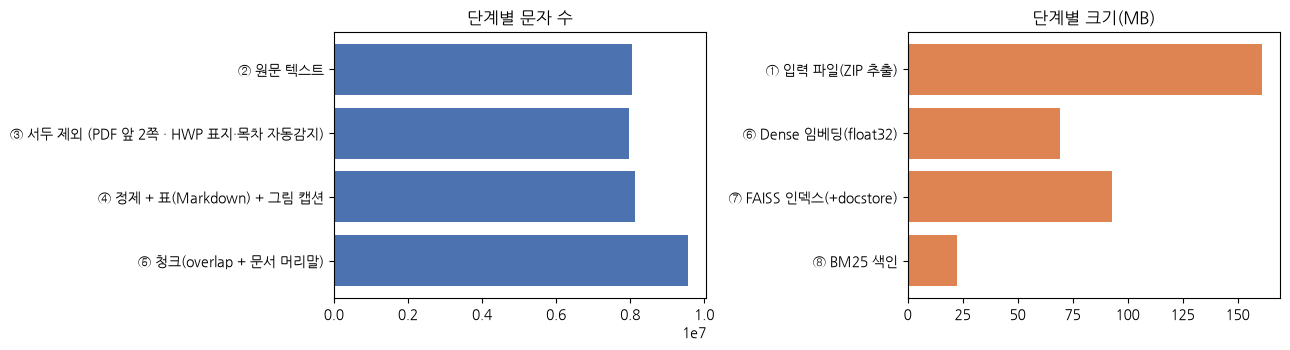

In [17]:
# 2-3) 📈 RAG 과정에서 데이터가 얼마나 늘어났는지
growth = nb.show_growth(pipe)

In [18]:
# 2-4) (선택) 리랭커 모델 미리 받기 + 효과 미리보기 — 02·03 에서 첫 질문이 다운로드로 멈추지 않게.  GPT·API 호출 없음 ($0)
PREFETCH_RERANKER = True
RERANK_MODEL = "BAAI/bge-reranker-v2-m3"      # 02·03 의 RERANK_MODEL 과 같게
from rag.retrieval import rerank_room, load_cross_encoder   # 02·03 과 같은 코드 (담당: 검색 · 리랭킹)
if PREFETCH_RERANKER:                          # 디스크·RAM 여유가 없으면 건너뜀 → 커널이 메모리 부족으로 죽지 않게
    _ok, _why = rerank_room(RERANK_MODEL)
    print(("✓ " if _ok else "⏭ 리랭커 미리 받기 건너뜀 — ") + _why + ("" if _ok else " · 02·03 에서 여유가 생기면 그때 받거나 RERANK=False 로 끄세요"))
    PREFETCH_RERANKER = _ok
if PREFETCH_RERANKER:
    import gc, torch
    _t = time.time()
    _ce = load_cross_encoder(RERANK_MODEL)
    print(f"🎯 리랭커 준비 {RERANK_MODEL} · {time.time() - _t:.1f}s (첫 실행은 약 2.3GB 다운로드 → 이후 캐시) · {gpu_mem()}")
    _q = "사업 예산과 사업 기간"
    _hits = retriever.search(_q, top_k=20)
    _sc = _ce.predict([(_q, h["text"]) for h in _hits], show_progress_bar=False)
    _order = sorted(range(len(_hits)), key=lambda i: -_sc[i])
    display(pd.DataFrame([{"리랭커 순위": k + 1, "하이브리드 순위": i + 1, "리랭커 점수": round(float(_sc[i]), 3),
                           "문서": _hits[i]["source"][:30], "섹션": (_hits[i].get("section") or "")[:40]} for k, i in enumerate(_order[:5])])
            .set_index("리랭커 순위").rename_axis(f"'{_q}' — 하이브리드 후보 20개 → 리랭커 TOP 5"))
    del _ce
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("💵 이 셀의 GPT 사용: 없음 ($0) · 리랭커 모델은 메모리에서 내림 (02·03 에서 다시 올림)")

⏭ 리랭커 미리 받기 건너뜀 — RAM 여유 3.6GB — 리랭커를 올리려면 4GB 이상 필요 (다른 노트북 커널을 끄세요) · 02·03 에서 여유가 생기면 그때 받거나 RERANK=False 로 끄세요


## 2-5 ~ 2-7. 🔎 검색(Retrieval) 과정 자체 평가 — GPT 없음 ($0)
> 👥 **담당:** 검색 · 리랭킹 — `rag/stage_eval.py`

답변을 만들지 않고 **검색 단계만** 채점합니다. 정답 = 질문마다 *근거가 들어 있는 문서(파일명 조각)* 와 *근거 키워드*.

| 지표 | 뜻 |
|---|---|
| **Hit@k** | 상위 k개 안에 정답 문서의 청크가 하나라도 있나 (0/1) |
| **Recall@k** | 정답 문서가 여러 개일 때(비교 질문) 몇 개를 찾았나 |
| **MRR** | 정답 문서가 처음 나온 순위의 역수 (1위 = 1, 2위 = 0.5, …) |
| **Precision@k** | 상위 k개 중 정답 문서 청크의 비율 |
| **Keyword@k** | 근거 키워드가 상위 k개 본문에 들어 있는 비율 (문서는 맞는데 엉뚱한 부분을 가져왔는지) |
| **점수 분리 AUC** | 문서 안 질문의 top1 점수가 문서 밖 질문보다 높을 확률 (관련도로 '모른다'를 가를 수 있는지) |

- `2-5` 정답 세트 → `2-6` 방식별 · k별 비교 → `2-7` Dense:BM25 가중치 스윕 + 저장 (`eval/results/retrieval_01.json`)
- 인덱스를 이미 만들었다면 커널 재시작 후 `0-1 → 0-2 → 0-3 → 2-5` 부터 실행해도 됩니다 (파싱·임베딩 다시 안 함).
- 여기 점수는 **질문을 그대로** 검색한 결과입니다. GPT 질문 해석(02·03 의 ①)은 포함되지 않습니다 → 02·03 의 검색이 이보다 좋다면 그만큼이 질문 해석의 효과입니다.

In [19]:
# 2-5) 🔎 검색 평가용 정답 세트 — 질문 · 정답 문서(파일명 조각) · 근거 키워드.  GPT 없음 ($0)
#   ▸ RFP 인덱스에 답이 있는 질문이어야 검색을 채점할 수 있습니다. type="ood" = 문서 밖 질문(점수 분리 · 거절 평가용)
#   ▸ docs=[["기관명", "사업명 조각"]] : 파일명에 조각이 모두 들어 있으면 정답 문서 ('A|B' = 둘 중 하나). 비교 질문은 문서를 여러 개
#   ▸ 고친 세트는 eval/retrieval_golden.jsonl 에 저장 → 02 · 03 · 04 가 같은 정답을 씀
import importlib
import rag.stage_eval as SE
importlib.reload(SE)

USE_SAVED_GOLD = True        # True: eval/retrieval_golden.jsonl 이 있으면 그것을 사용 (직접 고쳐 저장한 경우) · False: 기본 세트로 초기화
RETRIEVAL_GOLD = SE.load_gold() if USE_SAVED_GOLD else [dict(g) for g in SE.DEFAULT_RFP_GOLD]
# 질문 추가 예) RETRIEVAL_GOLD.append(dict(id="R09", question="…", docs=[["기관명", "사업명 조각"]], keywords=["근거에 있어야 할 말"]))

if globals().get("retriever") is None:          # 3-1 을 이미 실행했거나 커널을 새로 켠 경우 → 저장된 인덱스 다시 읽기
    retriever = pipe.load_retriever()
SOURCES = SE.corpus_sources(retriever)
gold_chk = SE.check_gold(RETRIEVAL_GOLD, SOURCES)
display(gold_chk.style.hide(axis="index").set_properties(**{"text-align": "left"}))
n_in = sum(g.get("type", "in") != "ood" for g in RETRIEVAL_GOLD)
print(f"인덱스 문서 {len(SOURCES)}개 · 정답 세트 {len(RETRIEVAL_GOLD)}개 (문서 안 {n_in} · 문서 밖 {len(RETRIEVAL_GOLD) - n_in})")
_bad = gold_chk[gold_chk["맞는 문서 수"] == 0]
for _, b in _bad.iterrows():                      # 맞는 파일이 없으면 비슷한 파일명을 보여줌 → docs 를 고치기 쉽게
    _first = b["정답 문서 패턴"].split(" + ")[0].split("|")
    _near = [s for s in SOURCES if any(SE.norm(a)[:3] in SE.norm(s) for a in _first)][:5]
    print(f"❌ {b['id']} '{b['정답 문서 패턴']}' — 비슷한 파일명: {_near or '없음'}")
if len(_bad):
    print("→ 위 파일명을 보고 RETRIEVAL_GOLD 의 docs 를 고친 뒤 이 셀을 다시 실행하세요 (맞는 문서가 0개인 질문은 Hit 가 항상 0)")
print("저장:", SE.save_gold(RETRIEVAL_GOLD))

id,정답 문서 패턴,맞는 문서 수,맞는 문서,상태
R01,국민연금공단 + 이러닝,1,국민연금공단_2024년 이러닝시스템 운영 용역.hwp,✅
R02,국민연금공단 + 이러닝,1,국민연금공단_2024년 이러닝시스템 운영 용역.hwp,✅
R03,기초과학연구원|중이온가속기,1,기초과학연구원_2025년도 중이온가속기용 극저온시스템 운전 용역.pdf,✅
R04,기초과학연구원|중이온가속기,1,기초과학연구원_2025년도 중이온가속기용 극저온시스템 운전 용역.pdf,✅
R05,한국원자력연구원,1,한국원자력연구원_한국원자력연구원 선량평가시스템 고도화.hwp,✅
R06,고려대학교 + 포털,1,고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf,✅
R06,광주과학기술원 + 학사,1,광주과학기술원_학사시스템 기능개선 사업.hwp,✅
R07,고려대학교 + 포털,1,고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf,✅
R07,광주과학기술원 + 학사,1,광주과학기술원_학사시스템 기능개선 사업.hwp,✅
R08,고려대학교 + 포털,1,고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf,✅


인덱스 문서 98개 · 정답 세트 11개 (문서 안 8 · 문서 밖 3)
저장: eval/retrieval_golden.jsonl


In [20]:
# 2-6) 🔎 검색 방식별 · k별 평가 — 같은 정답 세트로 FAISS 직접 · Dense · BM25 · 하이브리드 · 하이브리드+리랭커 비교.  GPT 없음 ($0)
#   FAISS 직접 : 벡터 검색만 (라우팅 없음)         dense / bm25 : 하이브리드 검색기에서 가중치를 1.0 / 0.0 으로 (라우팅 포함)
#   hybrid     : 지금 설정 그대로 (02 · 03 과 같은 검색)   hybrid+rerank : hybrid 후보 → 리랭커(내 GPU · RAM 4GB 이상 필요)
EVAL_KS = [1, 3, 5, 10]
K_MAIN = 5                                      # 02 · 03 의 TOP_K 와 같게
EVAL_MODES = ["FAISS 직접", "dense", "bm25", "hybrid", "hybrid+rerank"]     # 빼고 싶은 방식은 지우세요
RERANK_MODEL = globals().get("RERANK_MODEL") or "BAAI/bge-reranker-v2-m3"
RERANK_CANDIDATES = 30                          # 02 · 03 의 RERANK_CANDIDATES 와 같게
import gc
from contextlib import contextmanager
from IPython.display import Markdown

R_CFG = pipe.cfg["retrieval"]
print(f"지금 검색 설정: dense_weight {R_CFG.get('dense_weight')} · fusion {R_CFG.get('fusion')} · candidate_k {R_CFG.get('candidate_k')}"
      f" · 라우팅 {'켜짐' if getattr(retriever, 'router', None) else '꺼짐'}")


@contextmanager
def retriever_with(**overrides):
    """검색 설정만 바꾼 검색기 — 같은 인덱스 파일을 다시 읽음 (재구축 · 임베딩 없음). 끝나면 설정 원래대로"""
    old = {k: R_CFG.get(k) for k in overrides}
    R_CFG.update(overrides)
    r = pipe.load_retriever()
    try:
        yield r
    finally:
        R_CFG.update(old)
        del r
        gc.collect()


def search_with(r):
    return lambda q, k: SE.hits_from_retriever(r.search(q, top_k=k))


MODE_DF, MODE_RAW, MODE_SUM = {}, {}, {}
_h = display(Markdown("⏳ 검색 평가 준비…"), display_id=True)


def run_mode(mode, fn):
    t0 = time.time()
    df, raw = SE.evaluate_retrieval(RETRIEVAL_GOLD, fn, EVAL_KS, mode=mode,
                                    on_progress=lambda i, n, q: _h.update(Markdown(f"🔎 **{mode}** {i}/{n} · {q}")))
    MODE_DF[mode], MODE_RAW[mode] = df, raw
    MODE_SUM[mode] = {**SE.retrieval_summary(df, EVAL_KS), "소요(s)": round(time.time() - t0, 1)}


for mode in EVAL_MODES:
    try:
        if mode == "FAISS 직접":
            _st = retriever.store
            run_mode(mode, lambda q, k: SE.hits_from_langchain(_st.similarity_search_with_score(q, k=k)))
        elif mode == "hybrid":
            run_mode(mode, search_with(retriever))
        elif mode in ("dense", "bm25"):
            with retriever_with(dense_weight=1.0 if mode == "dense" else 0.0, fusion="score") as _r:
                run_mode(mode, search_with(_r))
        elif mode == "hybrid+rerank":
            from rag.retrieval import rerank_room, load_cross_encoder
            _ok, _why = rerank_room(RERANK_MODEL)
            if not _ok:
                print(f"⏭ hybrid+rerank 건너뜀 — {_why}")
                continue
            _ce = load_cross_encoder(RERANK_MODEL)

            def _rerank_search(q, k):
                cand = SE.hits_from_retriever(retriever.search(q, top_k=max(RERANK_CANDIDATES, k)))
                if not cand:
                    return []
                sc = _ce.predict([(q, c["text"]) for c in cand], show_progress_bar=False)
                order = sorted(range(len(cand)), key=lambda i: -float(sc[i]))
                return [{**cand[i], "score": float(sc[i])} for i in order[:k]]
            run_mode(mode, _rerank_search)
            del _ce
            gc.collect()
            try:
                import torch
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            except ImportError:
                pass
    except Exception as e:
        print(f"⚠️ {mode} 실패 — {type(e).__name__}: {e}")
_h.update(Markdown(f"✅ 검색 평가 완료 — 방식 {len(MODE_SUM)}개 × 질문 {len(RETRIEVAL_GOLD)}개 · GPT 호출 0회 ($0)"))

# 설정을 바꿨는데 결과가 그대로면 경고 (검색기가 설정을 다시 읽지 않거나, 라우팅으로 문서가 1개로 좁혀진 경우)
if {"dense", "bm25"} <= set(MODE_RAW) and SE.ranking_signature(MODE_RAW["dense"]) == SE.ranking_signature(MODE_RAW["bm25"]):
    print("⚠️ dense 와 bm25 결과가 완전히 같습니다 → load_retriever() 가 바뀐 가중치를 읽지 않는 것 같습니다. "
          "dense/bm25 · 2-7 스윕 결과는 참고하지 마세요 (FAISS 직접 · hybrid · 리랭커 비교는 유효)")

MAIN_COLS = [f"Hit@{K_MAIN}", f"Recall@{K_MAIN}", "MRR", f"Precision@{K_MAIN}", f"Keyword@{K_MAIN}", "평균 검색(s)", "소요(s)"]
cmp_df = pd.DataFrame(MODE_SUM).T.reindex(columns=MAIN_COLS).astype(float).rename_axis("검색 방식")
_sc = [c for c in MAIN_COLS if "(s)" not in c]
display(Markdown(f"### ① 검색 방식별 (k={K_MAIN}, 문서 안 질문 {n_in}개 평균)"),
        cmp_df.style.format("{:.3f}", subset=_sc, na_rep="—").format("{:.2f}", subset=["평균 검색(s)", "소요(s)"], na_rep="—")
        .background_gradient(subset=_sc, cmap="RdYlGn", vmin=0, vmax=1))
kcurve = pd.DataFrame({m: {f"Hit@{k}": s.get(f"Hit@{k}") for k in EVAL_KS} for m, s in MODE_SUM.items()}).T.astype(float)
kcurve = kcurve.join(pd.DataFrame({m: {f"Keyword@{k}": s.get(f"Keyword@{k}") for k in EVAL_KS} for m, s in MODE_SUM.items()}).T.astype(float))
display(Markdown("### ② k 를 늘리면 (Hit@k · Keyword@k) — TOP_K 를 정할 때 참고"),
        kcurve.style.format("{:.3f}", na_rep="—").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))
MAIN_MODE = "hybrid" if "hybrid" in MODE_DF else next(iter(MODE_DF), None)
if MAIN_MODE:
    _q = MODE_DF[MAIN_MODE]
    _qc = ["id", "type", "질문", "첫 정답 순위", f"Hit@{K_MAIN}", f"Recall@{K_MAIN}", "MRR", f"Precision@{K_MAIN}", f"Keyword@{K_MAIN}", "top1 점수", "top 문서"]
    _num = [f"Hit@{K_MAIN}", f"Recall@{K_MAIN}", "MRR", f"Precision@{K_MAIN}", f"Keyword@{K_MAIN}"]
    display(Markdown(f"### ③ 질문별 ({MAIN_MODE}) — Hit 이 0 인 질문이 검색 실패"),
            _q[_qc].style.format("{:.2f}", subset=_num + ["top1 점수"], na_rep="—")
            .background_gradient(subset=_num, cmap="RdYlGn", vmin=0, vmax=1)
            .set_properties(subset=["질문", "top 문서"], **{"text-align": "left"}).hide(axis="index"))
# ④ 관련도 점수로 문서 밖 질문을 가를 수 있는가 (FAISS 코사인 top1)
SEPARATION = {}
if "FAISS 직접" in MODE_DF:
    _fa = MODE_DF["FAISS 직접"]
    SEPARATION = SE.score_separation(_fa.loc[_fa["type"] != "ood", "top1 점수"], _fa.loc[_fa["type"] == "ood", "top1 점수"])
    display(Markdown("### ④ 문서 안 vs 문서 밖 질문의 top1 유사도 (FAISS 코사인)"),
            pd.DataFrame([SEPARATION]).style.format({k: "{:.3f}" for k, v in SEPARATION.items() if isinstance(v, float)}, na_rep="—").hide(axis="index"))
print("💵 이 셀의 GPT 사용: 없음 ($0)")

지금 검색 설정: dense_weight 0.6 · fusion score · candidate_k 50 · 라우팅 켜짐


✅ 검색 평가 완료 — 방식 4개 × 질문 11개 · GPT 호출 0회 ($0)

⏭ hybrid+rerank 건너뜀 — RAM 여유 2.4GB — 리랭커를 올리려면 4GB 이상 필요 (다른 노트북 커널을 끄세요)
⚠️ dense 와 bm25 결과가 완전히 같습니다 → load_retriever() 가 바뀐 가중치를 읽지 않는 것 같습니다. dense/bm25 · 2-7 스윕 결과는 참고하지 마세요 (FAISS 직접 · hybrid · 리랭커 비교는 유효)


### ① 검색 방식별 (k=5, 문서 안 질문 8개 평균)

,Hit@5,Recall@5,MRR,Precision@5,Keyword@5,평균 검색(s),소요(s)
검색 방식,,,,,,,
FAISS 직접,1.000,1.000,1.000,0.975,0.938,0.04,0.50
dense,1.000,1.000,1.000,0.925,1.000,0.43,4.70
bm25,1.000,1.000,1.000,0.925,1.000,0.40,4.40
hybrid,1.000,1.000,1.000,0.925,1.000,0.42,4.60


...

### ③ 질문별 (hybrid) — Hit 이 0 인 질문이 검색 실패

id,type,질문,첫 정답 순위,Hit@5,Recall@5,MRR,Precision@5,Keyword@5,top1 점수,top 문서
R01,in,국민연금공단이 발주한 이러닝시스템 관련 사업 요구사항을 정리해 줘.,1.000000,1.00,1.00,1.00,1.00,1.00,0.78,국민연금공단_2024년 이러닝시스템 운영 용역.hw
R02,in,국민연금공단 이러닝시스템 사업의 콘텐츠 개발 관리 요구사항을 자세히 알려 줘.,1.000000,1.00,1.00,1.00,1.00,1.00,0.80,국민연금공단_2024년 이러닝시스템 운영 용역.hw
R03,in,기초과학연구원 극저온시스템 사업 요구에서 AI 기반 예측에 대한 요구사항이 있나?,1.000000,1.00,1.00,1.00,0.80,1.00,0.56,기초과학연구원_2025년도 중이온가속기용 극저온시스
R04,in,기초과학연구원 극저온시스템 사업에서 모니터링 업무에 대한 요청사항이 있나?,1.000000,1.00,1.00,1.00,1.00,1.00,0.94,기초과학연구원_2025년도 중이온가속기용 극저온시스
R05,in,"한국 원자력 연구원에서 선량 평가 시스템 고도화 사업을 발주했는데, 이 사업이 왜 추진되는지 목적을 알려 줘.",1.000000,1.00,1.00,1.00,1.00,1.00,0.81,한국원자력연구원_한국원자력연구원 선량평가시스템 고도
R06,in,고려대학교 차세대 포털 시스템 사업이랑 광주과학기술원의 학사 시스템 기능개선 사업을 비교해 줄래?,1.000000,1.00,1.00,1.00,1.00,1.00,0.67,고려대학교_차세대 포털·학사 정보시스템 구축사업.p
R07,in,고려대학교랑 광주과학기술원 각각 응답 시간에 대한 요구사항이 있나? 문서를 기반으로 정확하게 답변해 줘.,1.000000,1.00,1.00,1.00,0.60,1.00,0.74,광주과학기술원_학사시스템 기능개선 사업.hwp / 광주과학기술원_실시간통합연구비관리시스템(RCMS)
R08,in,고려대 차세대 포탈 학사시스템 구축 사업 예산이 얼마야?,1.000000,1.00,1.00,1.00,1.00,1.00,0.73,고려대학교_차세대 포털·학사 정보시스템 구축사업.p
X01,ood,월세액 세액공제 한도가 얼마예요?,nan,—,—,—,—,—,0.50,한국철도공사 (용역)_[재공고][긴급][협상형]운행 / 한국수출입은행_(긴급) 모잠비크 마푸토 지능형교통시 / 한국건강가정진흥원_2025년 아이돌봄인력 인적성 검
X02,ood,연말정산은 언제 하나요?,nan,—,—,—,—,—,1.00,인천공항운영서비스(주)_인천공항운영서비스㈜ 차세대 / 한국농수산식품유통공사_농산물가격안정기금 정부예산회계


### ④ 문서 안 vs 문서 밖 질문의 top1 유사도 (FAISS 코사인)

문서 안 평균,문서 안 최소,문서 밖 평균,문서 밖 최대,AUC,추천 임계값,판정
0.703,0.611,0.503,0.569,1.000,0.590,✅ 완전히 분리됨


💵 이 셀의 GPT 사용: 없음 ($0)


In [21]:
# 2-7) ⚖️ Dense : BM25 가중치 스윕 + 검색 평가 저장 → eval/results/retrieval_01.json (02 · 04 가 사용).  GPT 없음 ($0)
RUN_SWEEP = True
SWEEP_DENSE_WEIGHTS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SWEEP_FUSION = "score"                          # 02 · 03 의 FUSION 과 같게
sweep_df, _sigs = pd.DataFrame(), set()
if RUN_SWEEP:
    _rows = []
    _hs = display(Markdown("⏳ 스윕 준비…"), display_id=True)
    for w in SWEEP_DENSE_WEIGHTS:
        _hs.update(Markdown(f"⚖️ Dense {w:.0%} : BM25 {1 - w:.0%} 평가 중…"))
        with retriever_with(dense_weight=w, fusion=SWEEP_FUSION) as _r:
            _df, _raw = SE.evaluate_retrieval(RETRIEVAL_GOLD, search_with(_r), EVAL_KS, mode=f"dense={w}")
        _s = SE.retrieval_summary(_df, EVAL_KS)
        _sigs.add(SE.ranking_signature(_raw))
        _rows.append({"Dense 비율": w, "BM25 비율": round(1 - w, 2), **{c: _s.get(c) for c in MAIN_COLS if c != "소요(s)"}})
    sweep_df = pd.DataFrame(_rows)
    _hs.update(Markdown(f"✅ 스윕 완료 — {len(SWEEP_DENSE_WEIGHTS)}개 비율 · fusion={SWEEP_FUSION}"))
    _sc = [c for c in MAIN_COLS if "(s)" not in c]
    display(sweep_df.style.format("{:.3f}", subset=_sc, na_rep="—").format("{:.0%}", subset=["Dense 비율", "BM25 비율"])
            .format("{:.2f}", subset=["평균 검색(s)"], na_rep="—").background_gradient(subset=_sc, cmap="RdYlGn", vmin=0, vmax=1).hide(axis="index"))
    if len(_sigs) == 1:
        print("⚠️ 모든 비율에서 검색 결과가 똑같습니다 → 검색기가 바뀐 가중치를 읽지 않거나(라우팅으로 문서가 좁혀진 경우 포함) 정답 세트가 너무 쉬움. 추천값을 쓰지 마세요")
    else:
        _best = sweep_df.sort_values([f"Hit@{K_MAIN}", "MRR", f"Keyword@{K_MAIN}", "Dense 비율"], ascending=[False, False, False, False]).iloc[0]
        print(f"→ 이 정답 세트 기준 추천 DENSE_WEIGHT = {_best['Dense 비율']:.1f} (Hit@{K_MAIN} {_best[f'Hit@{K_MAIN}']:.3f} · MRR {_best['MRR']:.3f})"
              " — 02 · 03 의 0-2 DENSE_WEIGHT 에 반영해 보세요. 질문이 적으면(10개 안팎) 차이가 우연일 수 있습니다")

RETRIEVAL_EVAL_SUMMARY = {m: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items()
                              if k in (f"Hit@{K_MAIN}", f"Recall@{K_MAIN}", "MRR", f"Keyword@{K_MAIN}")} for m, s in MODE_SUM.items()}
_saved = SE.save_result("retrieval_01", {
    "stage": "retrieval", "notebook": "01_rag_build",
    "meta": {"embed_model": pipe.active.get("embed_model"), "chunk_size": CFG["chunking"]["chunk_size"],
             "overlap_ratio": CFG["chunking"].get("overlap_ratio"), "faiss": CFG["faiss"].get("index_type"),
             "bm25": CFG.get("bm25"), "retrieval": dict(R_CFG), "documents": len(SOURCES), "k_main": K_MAIN, "ks": EVAL_KS,
             "rerank_model": RERANK_MODEL if "hybrid+rerank" in MODE_SUM else None, "main_mode": MAIN_MODE},
    "gold": RETRIEVAL_GOLD, "gold_check": gold_chk,
    "modes": {m: {"summary": MODE_SUM[m], "rows": MODE_DF[m]} for m in MODE_DF},
    "sweep": sweep_df, "separation": SEPARATION})
print("저장:", _saved, "· 💵 이 셀의 GPT 사용: 없음 ($0)")

✅ 스윕 완료 — 6개 비율 · fusion=score

Dense 비율,BM25 비율,Hit@5,Recall@5,MRR,Precision@5,Keyword@5,평균 검색(s)
0%,100%,1.000,1.000,1.000,0.925,1.000,0.50
20%,80%,1.000,1.000,1.000,0.925,1.000,0.39
40%,60%,1.000,1.000,1.000,0.925,1.000,0.40
60%,40%,1.000,1.000,1.000,0.925,1.000,0.40
80%,20%,1.000,1.000,1.000,0.925,1.000,0.37
100%,0%,1.000,1.000,1.000,0.925,1.000,0.38


⚠️ 모든 비율에서 검색 결과가 똑같습니다 → 검색기가 바뀐 가중치를 읽지 않거나(라우팅으로 문서가 좁혀진 경우 포함) 정답 세트가 너무 쉬움. 추천값을 쓰지 마세요
저장: eval/results/retrieval_01.json · 💵 이 셀의 GPT 사용: 없음 ($0)


## 3. ✅ 학습 결과 저장 → 02 노트북에서 사용
> 👥 **담당:** 청크 · 색인 (01 노트북 책임자)

In [22]:
# 3-1) 인덱스를 만든 설정 + 인덱스 경로(active.json)를 artifacts/build_config.json 에 저장
saved = pipe.save_build_config(extra={"profile": profile_name(HW), "gpu": HW.get("gpu"), "cpu": HW.get("cpu_model"),
                                      "chunks": len(chunks) if chunks else None})
print("저장:", saved)
build_params = nb.final_params(CFG, extra={"프로필": profile_name(HW), "GPU": HW.get("gpu"), "CPU": HW.get("cpu_model"),
                                           "torch / CUDA": f"{HW.get('torch')} / {HW.get('cuda')}", "NVIDIA 드라이버": HW.get("gpu_driver"),
                                           "청크 수": len(chunks) if chunks else None,
                                           "임베딩 모델(인덱스)": pipe.active.get("embed_model"),
                                           "FAISS": pipe.active.get("faiss_dir"), "BM25": pipe.active.get("bm25_path"),
                                           "검색 평가(2-6)": globals().get("RETRIEVAL_EVAL_SUMMARY")},
                               save_to=str(Path(WORK_DIR) / "build_params.json"))
# 메모리 반환 — 02·03 을 같은 VM 에서 돌릴 때 이 커널이 RAM·GPU 를 붙잡고 있으면 메모리 부족(OOM)으로 커널이 강제 종료될 수 있음
import gc
for _name in ("retriever", "store", "docs", "chunks", "quality", "size_cmp", "growth", "hdocs", "raw", "txt", "body", "front",
              "MODE_DF", "MODE_RAW", "_st", "_r", "_ce"):
    globals().pop(_name, None)
from rag.indexing import HFEmbedder
HFEmbedder.clear_cache()
gc.collect()
print(f"메모리 반환 → 이 커널 RAM {psutil.Process().memory_info().rss / 1024**3:.1f}GB · 사용 가능 "
      f"{psutil.virtual_memory().available / 1024**3:.1f}GB · {gpu_mem()}")
print("➡️ 이 노트북의 커널을 종료(VS Code: 노트북 위 '…' ▸ 커널 종료 / 탭 닫을 때 커널도 종료)한 뒤 "
      "02_generate_eval.ipynb 또는 03_chatbot.ipynb 를 실행하세요 — 노트북은 한 번에 하나만 (RAM 16GB)")

저장: artifacts/build_config.json


,구분,파라미터,값
0,로더(라이브러리),pdf_text_loader,PyPDFLoader
1,로더(라이브러리),pypdf,"{""mode"": ""page"", ""extraction_mode"": ""plain"", ""extraction_kwargs"": {}}"
2,로더(라이브러리),pdf_table_loader,PyMuPDFLoader
3,로더(라이브러리),table_settings,{}
4,로더(라이브러리),image_parser,hf-vlm
...,...,...,...
66,추가,청크 수,17695
67,추가,임베딩 모델(인덱스),nlpai-lab/KURE-v1
68,추가,FAISS,artifacts/faiss/29037eb6f129
69,추가,BM25,artifacts/bm25/bm25_79a058a3c0a6.pkl


메모리 반환 → 이 커널 RAM 4.5GB · 사용 가능 2.7GB · GPU 메모리: 이 프로세스 1.07GB(예약 2.09GB) · 장치 여유 19.7 / 22.0GB
➡️ 이 노트북의 커널을 종료(VS Code: 노트북 위 '…' ▸ 커널 종료 / 탭 닫을 때 커널도 종료)한 뒤 02_generate_eval.ipynb 또는 03_chatbot.ipynb 를 실행하세요 — 노트북은 한 번에 하나만 (RAM 16GB)
